In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import nltk
import seaborn as sns
from matplotlib.ticker import AutoMinorLocator
import re
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity
from nltk.stem import WordNetLemmatizer

lemmatizer = WordNetLemmatizer()
model = SentenceTransformer("all-MiniLM-L6-v2")
nltk.download('wordnet')
nltk.download('omw-1.4')


c:\Users\hp\OneDrive\Desktop\Uni\Magistrale\TLN\Progetto_TLN\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 8636.29it/s]
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\hp\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\hp\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

# Data preprocessing

In [2]:
dataset = pd.read_csv("DatasetDefinizioni.csv")

df = dataset.drop(columns=['Risposta numero'])

df.rename(columns={
    "(AG) Definizione del concetto ASTRATTO e GENERICO": "AG",
    "(AS) Definizione del concetto ASTRATTO e SPECIFICO": "AS",
    "(CG) Definizione del concetto CONCRETO e GENERICO": "CG",
    "(CS) Definizione del concetto CONCRETO e SPECIFICO": "CS",
    "(CM) Definizione del concetto misterioso (complesso)": "CM"
}, inplace=True)

df = df.apply(lambda col: col.str.replace(r'\xa0', ' ', regex=True)
                               .str.replace(r'\s+', ' ', regex=True)
                               .str.strip()
                               .str.lower())


## Similarity

In [3]:
# transforms the input into a set of words, if the input is already a set it returns it as is, 
# if it's a string it splits it into words and returns a set of those words, otherwise it returns an empty set
def to_set(x):
    if isinstance(x, set):
        return x
    elif isinstance(x, str):
        return set(x.split())
    else:
        return set()

# used to compute Jaccard similarity it converts the input in sets 
# then calculate how many words are in common between the two sets 
def jaccard_similarity(a, b):
    set_a = to_set(a)
    set_b = to_set(b)

    intersection = set_a.intersection(set_b)
    union = set_a.union(set_b)

    return len(intersection) / len(union) if union else 0

# used to compute the overlap coefficient it converts the input in sets
# then calculate how many words are in common between the two sets and divide it by the size of the smaller set
def overlap_coefficient(a, b):
    set_a = to_set(a)
    set_b = to_set(b)

    intersection = set_a.intersection(set_b)
    min_size = min(len(set_a), len(set_b))

    return len(intersection) / min_size if min_size > 0 else 0

## Jaccard Similarity Across Concepts

The **Jaccard Similarity** between two texts is defined as:

$$J(A, B) = \frac{|A \cap B|}{|A \cup B|}$$

It measures the proportion of shared words, ranging from **0** (no overlap) to **1** (identical).

**Example:**
- *"A tree is a tall plant with a trunk"*
- *"A tree is a large plant that grows in forests"*

$$J = \frac{|\{a, tree, is, plant\}|}{|\{a, tree, is, tall, large, plant, ...\}|} = \frac{4}{12} \approx 0.33$$

For each concept, we average all pairwise similarities across definitions

The results show **low similarity** across all concepts (< 0.15), meaning participants used quite different vocabulary to describe the same concept. *Tree* scores highest (0.14), *Random* the lowest (0.06).

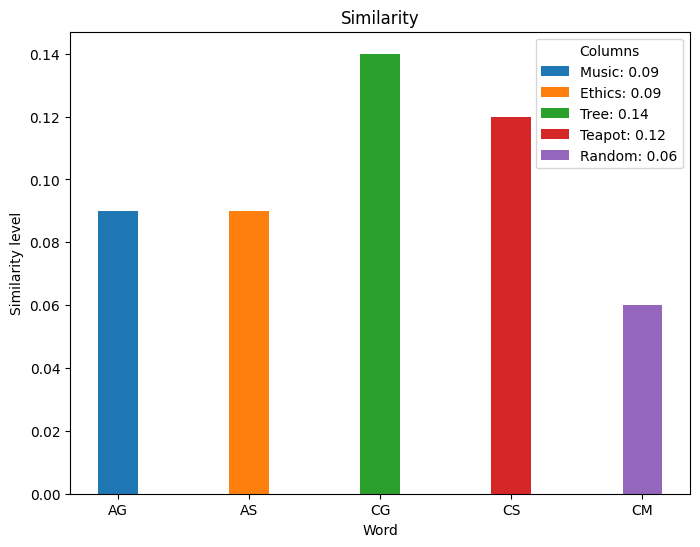

In [4]:
#{
# 'AG': 0.09, 
# 'AS': 0.09, 
# 'CG': 0.14, 
# 'CS': 0.12, 
# 'CM': 0.06
#}
similarity = {}

for col in df.columns:
    similarities = []

    defs = df[col].tolist()

    for i in range(len(defs)):
        for j in range(i + 1, len(defs)):
            # compute the Jaccard similarity between the two definitions and append it to the similarities list
            similarities.append(jaccard_similarity(defs[i], defs[j]))

    sim = 0
    if len(similarities) > 0:
        sim = sum(similarities) / len(similarities)

    similarity[col] = f"{sim:.2f}"

fig, ax = plt.subplots(figsize=(8, 6))

concepts = ['Music', 'Ethics', 'Tree', 'Teapot', 'Random']

for i, (col, val) in enumerate(similarity.items()):
    ax.bar(col, float(val), label=f'{concepts[i]}: {similarity[col]}', width=0.3)

ax.set_title('Similarity')
ax.set_xlabel('Word')
ax.set_ylabel('Similarity level')

ax.legend(title="Columns")


plt.show()

## Overlap Coefficient 

The **Overlap Coefficient** between two texts is defined as:

$$
Overlap(A, B) = \frac{|A \cap B|}{\min(|A|, |B|)}
$$

It measures how much the smaller text is contained within the larger one, ranging from **0** (no shared words) to **1** (complete inclusion of the smaller set).

**Example:**

- *"A tree is a tall plant with a trunk"*
- *"A tree is a plant"*

$$
Overlap = \frac{|\{a, tree, is, plant\}|}{\min(8, 5)} = \frac{4}{5} = 0.8
$$

For each concept, all possible pairs of definitions within the same column are compared, and a similarity score is computed for each pair using the overlap coefficient. Only pairs with a score greater than **0.1** are retained, and results are sorted to highlight the strongest overlaps.

The results show **limited overlap** across definitions, indicating that different words are used even when describing the same concept.

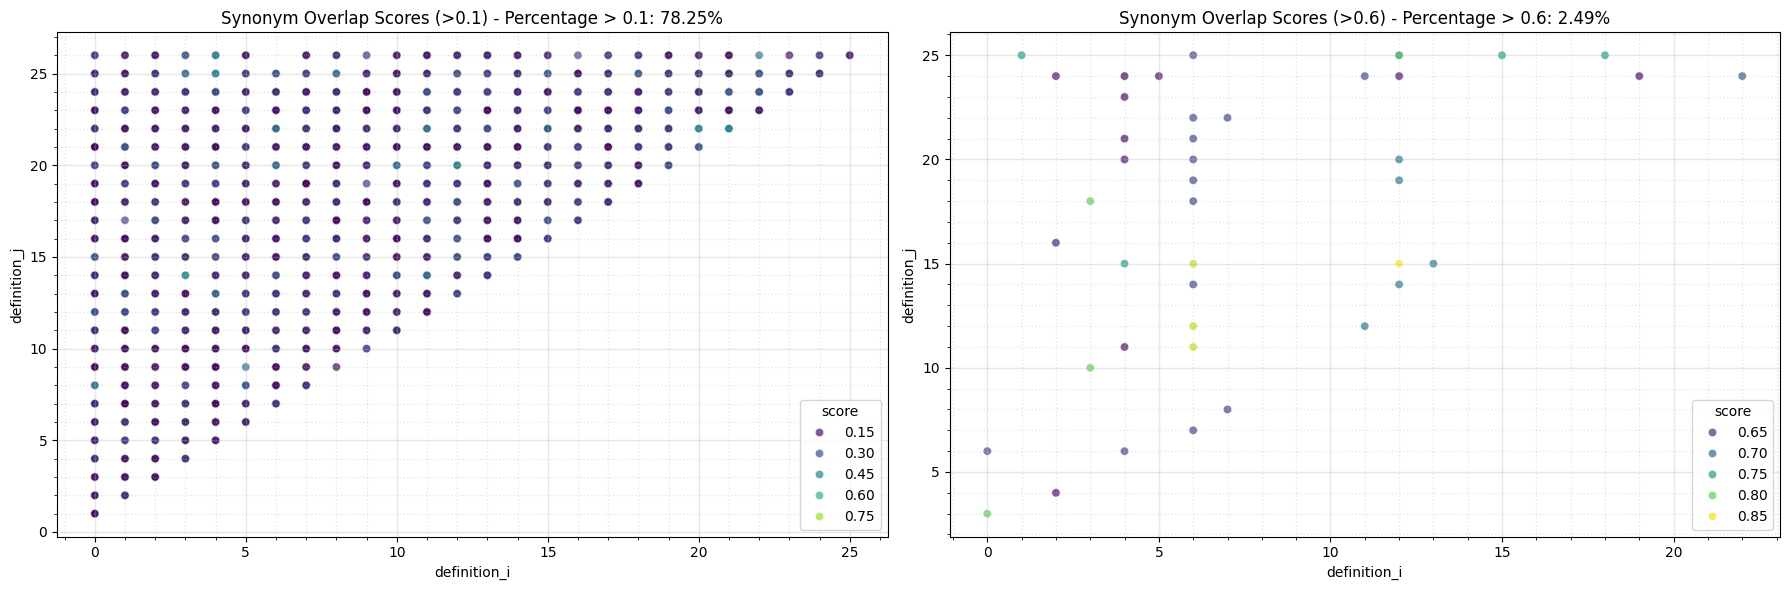

In [5]:
results = []

for col in df.columns:
    # get the definitions for the current column, drop any NaN values, and convert it to a list
    defs = df[col].dropna().tolist()

    for i in range(len(defs)):
        for j in range(i + 1, len(defs)):
            # compute the overlap coefficient between the two definitions and append the result to the results list
            score = overlap_coefficient(defs[i], defs[j])

            results.append({
                "column": col,
                "definition_i": i,
                "definition_j": j,
                "score": score
            })

synonym_df = pd.DataFrame(results)

# filter the synonym_df to include only rows where the score is greater than 0.1
synonym_df_10 = synonym_df[synonym_df['score'] > 0.1].sort_values(by='score', ascending=False)
synonym_df_60 = synonym_df[synonym_df['score'] > 0.6].sort_values(by='score', ascending=False)


# is considered just one pair of (x,y)
data_10 = synonym_df_10[synonym_df_10['definition_i'] < synonym_df_10['definition_j']]            
data_60 = synonym_df_60[synonym_df_60['definition_i'] < synonym_df_60['definition_j']]

total_pairs = len(synonym_df)

perc_01 = len(synonym_df_10) / total_pairs * 100
perc_06 = len(synonym_df_60) / total_pairs * 100

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

sns.scatterplot(
    data=data_10,
    x='definition_i',
    y='definition_j',
    hue='score',
    palette='viridis',
    alpha=0.7,
    ax=axes[0]
)

sns.scatterplot(
    data=data_60,
    x='definition_i',
    y='definition_j',
    hue='score',
    palette='viridis',
    alpha=0.7,
    ax=axes[1]
)

axes[0].set_title(f"Synonym Overlap Scores (>0.1) - Percentage > 0.1: {perc_01:.2f}%")
axes[0].grid(True, which='major', linestyle='-', linewidth=1, alpha=0.3)
axes[0].xaxis.set_minor_locator(AutoMinorLocator(5))
axes[0].yaxis.set_minor_locator(AutoMinorLocator(5))
axes[0].grid(True, which='minor', linestyle=':', linewidth=1, alpha=0.3)


axes[1].set_title(f"Synonym Overlap Scores (>0.6) - Percentage > 0.6: {perc_06:.2f}%")
axes[1].grid(True, which='major', linestyle='-', linewidth=1, alpha=0.3)
axes[1].xaxis.set_minor_locator(AutoMinorLocator(5))
axes[1].yaxis.set_minor_locator(AutoMinorLocator(5))
axes[1].grid(True, which='minor', linestyle=':', linewidth=1, alpha=0.3)

plt.tight_layout()
plt.show()



# SIMLEX - SIMSEM


## Common words
A **word frequency analysis** is performed after removing common stopwords (e.g., articles, prepositions, and auxiliary words that do not carry strong semantic meaning). For each concept, all definitions are concatenated, converted to lowercase, and tokenized into individual words. The frequency of each word is then computed, allowing us to identify the most characteristic terms associated with each concept.

The results show clear **thematic consistency within each column**, with high-frequency words strongly reflecting the underlying concept being described. For example, in Column AG (music), dominant terms such as *sounds*, *instruments*, and *musical* indicate a strong focus on auditory and artistic elements. In Column AS (ethics), frequent words like *human*, *moral*, *behavior*, and *philosophy* highlight the normative and philosophical nature of the concept. Column CG (tree) is characterized by highly structural and biological terms such as *plant*, *branches*, *leaves*, *trunk*, and *roots*, showing strong semantic coherence. Similarly, Column CS (teapot) is dominated by functional and object-related vocabulary such as *tea*, *container*, *water*, *pour*, and *ceramic*, reflecting its practical use. Finally, Column CM shows more heterogeneous concepts, but still includes recurring terms such as *mental*, *feeling*, *used*, and *system*.


Overall, while each concept shows a clear core vocabulary, the presence of lower-frequency and idiosyncratic terms indicates variability in how participants describe the same idea, with some responses being more structured and others more descriptive or divergent.

In [6]:
# list of common English stopwords
stopwords = [
    "a", "an", "the",
    "and", "or", "but", "if", "because",
    "as", "until", "while",
    "of", "at", "by", "for", "with",
    "about", "against", "between",
    "into", "through", "during",
    "before", "after", "above", "below",
    "to", "from", "up", "down", "in", "out", "on", "off", "over", "under",
    "again", "further", "then", "once",
    "here", "there", "when", "where", "why", "how",
    "all", "any", "both", "each", "few", "more", "most", "other", "some", "such",
    "no", "nor", "not", "only", "own", "same", "so", "than", "too", "very",
    "s", "t", "can", "will", "just", "don", "should", "now"
]

# function to count the frequency of words in a column, excluding stopwords
def get_column_counts(column):
    words = ' '.join(column.dropna().astype(str)).lower().split()

    word_dict = {}

    for word in words:
        if word not in stopwords:
            word_dict[word] = word_dict.get(word, 0) + 1

    return word_dict

# compute the word counts for each column in the DataFrame and store them in a list
counts_per_column = [get_column_counts(df[col]) for col in df.columns]

for i, counts in enumerate(counts_per_column):
    sorted_counts = sorted(counts.items(), key=lambda x: x[1], reverse=True)
    print(f"Column {df.columns[i]} - most frequent words: {sorted_counts[:5]}\n")


Column AG - most frequent words: [('sounds', 15), ('that', 8), ('be', 7), ('instruments', 7), ('produced', 6)]

Column AS - most frequent words: [('that', 22), ('human', 12), ('is', 11), ('what', 10), ('right', 9)]

Column CG - most frequent words: [('plant', 18), ('branches', 14), ('leaves', 14), ('it', 10), ('that', 10)]

Column CS - most frequent words: [('used', 25), ('tea', 13), ('container', 13), ('usually', 10), ('is', 8)]

Column CM - most frequent words: [('that', 7), ('used', 7), ('is', 6), ('it', 5), ('has', 4)]



## SIMLEX
## Lemmatization

For each column, an empty list is created to store processed definitions. Each definition is first checked for missing values; if a value is missing (`NaN`), `None` is appended to preserve alignment. Otherwise, the text is converted to lowercase and tokenized using a regular expression that extracts word-like units. Stopwords are removed to filter out non-informative terms. Each remaining word is then lemmatized using a lemmatizer to reduce it to its base form. The final result for each definition is stored as a set of unique lemmatized words. These sets are collected per column and assembled into a new DataFrame (`simlex_df`), where each cell contains a set representation of the corresponding definition, enabling set-based similarity analyses in later steps.

In [7]:
definitions = {}

for col in df.columns:
    definitions[col] = []

    for defn in df[col]:
        # if the definition is NaN, append None to the definitions list for the current column and continue to the next iteration
        if pd.isna(defn):
            definitions[col].append(None)
            continue


        def_set = {
            lemmatizer.lemmatize(word)  # reduce the word to its base form
            for word in re.findall(r'\b\w+\b', defn.lower())  # extract all word tokens from the lowercase text
            if word not in stopwords  # exclude common stopwords that do not carry semantic meaning
        }

        definitions[col].append(def_set)

simlex_df = pd.DataFrame(definitions)
simlex_df

,AG,AS,CG,CS,CM
0,"{have, melodious, part, sound, composed, vario...","{human, often, aimed, what, philosophical, per...","{root, obtain, branch, paper, produce, used, f...","{usually, boiling, leaf, water, tea, kitchen, ...","{feeling, discomfort, term, coined, millennial..."
1,"{set, sound, people, musical, instrument, simu...","{that, human, philosophy, incorrect, correct, ...","{root, generic, having, leaf, type, branch, di...","{usually, liquid, general, metal, container, h...","{thinking, content, result, abstract, mental, ..."
2,"{perceived, combination, those, auditory, be, ...","{according, quality, common, human, sentiment,...","{that, root, composed, ha, it, leaf, ground, b...","{hot, usually, mug, decant, it, leaf, beverage...","{human, control, like, product, joystick, inte..."
3,"{created, sound, musical, one, instrument}","{considered, that, science, philosophy, are, c...","{living, that, leaf, life, sometimes, being, b...","{tool, make, tea, used}","{be, feeling, discomfort, like, would, differe..."
4,"{keyboard, lyric, be, instrumental, drum, viol...","{whether, concentrate, sphere, permitted, lega...","{tunk, leaf, branch, plant, made}","{inside, lid, ha, beak, contains, handle, reci...",None
5,"{that, sound, human, be, organization, voice, ...","{that, human, philosophy, are, what, right, be...","{ground, nutriment, organism, usually, leaf, g...","{that, store, usually, teacup, be, liquid, tea...","{organism, these, leaf, gain, photosynthesis, ..."
6,"{sound, emotion, sequence, human, triggering, ...","{that, whether, wrong, ask, philosophy, are, r...","{branch, leaf, plant, woody}","{infusion, intended, often, ceramic, tea, cont...","{that, ha, purpose, system, water, engineering..."
7,"{sound, emotion, sequence, capable, listener, ...","{that, learned, principle, wrong, define, mora...","{root, composed, leaf, type, branch, plant, tr...","{ceramic, heat, water, prepare, tea, table, se...","{ability, japanese, various, consisting, typic..."
8,"{that, set, sound, heard, harmony, are}","{rule, set, shared, conventionally, unwritten}","{root, composed, leaf, organic, branch, born, ...","{holding, pouring, container, useful, tee}","{object, lens, graduated, used, use, improve, ..."
9,"{possibility, damage, condition, loss, is, har...","{that, decision, problem, heuristic, help, pos...","{object, practical, easily, perform, measuring...","{object, microscope, that, smalll, seen, be, c...","{place, help, it, direction, unfamiliar, corre..."


## Jaccard and Overlap Similarity Across Concepts

The similarity between definitions is measured using two set-based metrics: **Jaccard similarity** and the **Overlap Coefficient**.

The **Jaccard similarity** is defined as:

$$
J(A, B) = \frac{|A \cap B|}{|A \cup B|}
$$

It quantifies the proportion of shared words between two sets relative to their total unique words, ranging from **0** (no overlap) to **1** (identical sets).

The **Overlap Coefficient** is defined as:

$$
Overlap(A, B) = \frac{|A \cap B|}{\min(|A|, |B|)}
$$

It measures how much the smaller set is contained within the larger one, and therefore tends to produce higher values when one definition is largely included in another.

For each concept (column), all possible pairs of definitions are compared. For every pair, both Jaccard and Overlap scores are computed, and their values are averaged to obtain a global similarity measure per concept.

The results show a pattern across metrics. Jaccard similarity is generally low for all concepts, indicating limited shared vocabulary overall, with values ranging from approximately **0.01 (CM)** to **0.16 (CG)**. In contrast, Overlap scores are systematically higher, ranging from about **0.03 (CM)** to **0.39 (CG)**, reflecting partial inclusion relationships between definitions rather than full lexical agreement.

Across concepts, **CG (tree)** and **CS (teapot)** exhibit the highest similarity values in both metrics, suggesting more consistent and structured descriptions. **AG (music)** and **AS (ethics)** show moderate similarity, while **CM** consistently displays the lowest values, indicating highly heterogeneous and diverse definitions.

Jaccard: {'AG': 0.08502837675723296, 'AS': 0.08528133136141923, 'CG': 0.16116207279711237, 'CS': 0.13850758193042872, 'CM': 0.011860189335329578} 
Overlap: {'AG': 0.21828468023792308, 'AS': 0.18617447367447368, 'CG': 0.3884385558196783, 'CS': 0.3039968383105638, 'CM': 0.03248120255812564}


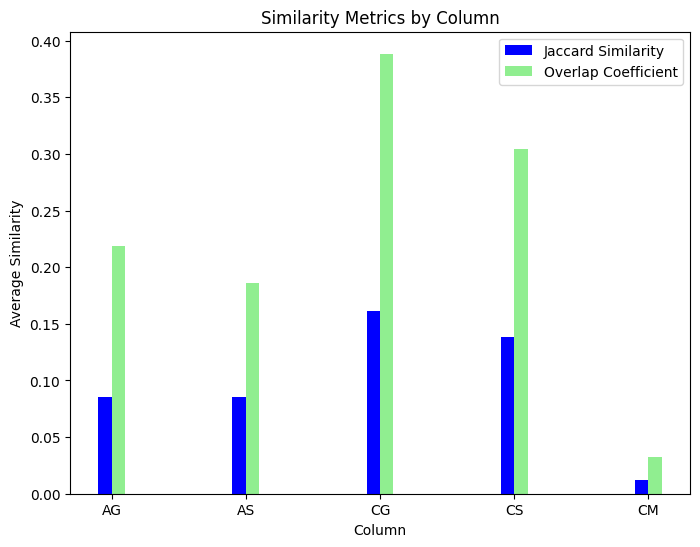

In [8]:
similarity_jaccard = {}
similarity_overlap = {}
simlex_dict = {}

for col in simlex_df.columns:
    jaccard_vals = []
    overlap_vals = []

    defs = simlex_df[col].dropna().tolist()

    for i in range(len(defs)):
        for j in range(i + 1, len(defs)):
            jaccard_vals.append(jaccard_similarity(defs[i], defs[j]))
            overlap_vals.append(overlap_coefficient(defs[i], defs[j]))
            simlex_dict[(col, i, j)] = jaccard_similarity(defs[i], defs[j])

    similarity_jaccard[col] = sum(jaccard_vals) / len(jaccard_vals) if jaccard_vals else 0
    similarity_overlap[col] = sum(overlap_vals) / len(overlap_vals) if overlap_vals else 0
    

print(f"Jaccard: {similarity_jaccard} \nOverlap: {similarity_overlap}")

bar_width = 0.10
positions = np.arange(len(similarity_jaccard))

fig, ax = plt.subplots(figsize=(8, 6))
ax.bar(positions - bar_width/2, list(similarity_jaccard.values()), width=bar_width, label='Jaccard Similarity', color='blue')
ax.bar(positions + bar_width/2, list(similarity_overlap.values()), width=bar_width, label='Overlap Coefficient', color='lightgreen')

ax.set_xticks(positions)
ax.set_xticklabels(similarity_jaccard.keys())

ax.set_title('Similarity Metrics by Column')
ax.set_xlabel('Column')
ax.set_ylabel('Average Similarity')
ax.legend()
plt.show()

## Simsem

## Vector rappresentation
## Cosine Similarity Across Concepts

The **Cosine Similarity** measures the semantic similarity between two texts by comparing their vector representations in an embedding space. It is defined as:

$$
\text{cosine}(A, B) = \frac{A \cdot B}{\|A\| \|B\|}
$$

It quantifies how similar two definitions are in meaning rather than exact word overlap, ranging from **0** (completely unrelated) to **1** (identical semantic content).

In this analysis, each definition is first converted into a sentence by joining its lemmatized word set. These sentences are then encoded into dense vector representations using a pretrained embedding model. For each column, all possible pairs of definitions are compared, and cosine similarity is computed between their embedding vectors.

Overall, cosine similarity captures deeper relationships between definitions, highlighting conceptual consistency even when different words are used. Higher values indicate that participants express similar meanings using different vocabulary, while lower values reflect greater semantic divergence across definitions.

In [9]:
cosine_dict = {}

for col in simlex_df.columns:
    defs = simlex_df[col].dropna().tolist()
    for i in range(len(defs)):
        for j in range(i + 1, len(defs)):
            ph1 = " ".join(defs[i])
            ph2 = " ".join(defs[j])
            def_1 = model.encode(ph1)
            def_2 = model.encode(ph2)

            # compute cosine similarity between the two embedding vectors and store the result
            # [0][0] is used to extract the single similarity value from the 2D array returned by cosine_similarity
            cosine_dict[(col, i, j)] = cosine_similarity([def_1], [def_2])[0][0]

In [10]:
greater_cosine_dict = {}
simsem_dict = {}

# filter the cosine_dict to include only pairs with cosine similarity greater than 0.8
for pair in cosine_dict:
    if cosine_dict[pair] > 0.8:
        greater_cosine_dict[pair] = cosine_dict[pair]

print(f"Percentage of pairs with cosine similarity > 0.8: {len(greater_cosine_dict) / len(cosine_dict) * 100:.2f}% \nTotal pairs: {len(cosine_dict)} \nGreater cosine: {len(greater_cosine_dict)}\n")

# greater_cosine_dict
for pair in greater_cosine_dict:
    print(f"{pair}: {greater_cosine_dict[pair]:.4f}, \n{df.loc[pair[1], pair[0]]} \n{df.loc[pair[2], pair[0]]}\n")



Percentage of pairs with cosine similarity > 0.8: 0.64% 
Total pairs: 1729 
Greater cosine: 11

('AS', 1, 24): 0.8067, 
branch of philosophy that focuses on defining correct and incorrect human behavior. 
branch of philosophy that studies human behavior by trying to define what is right and what is wrong.

('AS', 22, 24): 0.8071, 
branch of philosophy that studies human behavior, and in particular analyzes what is right or wrong, and what collective behaviors lead to good or evil. 
branch of philosophy that studies human behavior by trying to define what is right and what is wrong.

('CG', 1, 24): 0.8726, 
plant, with different types and generic size, having leaves, branches, roots. 
plant of generic dimensions, composed of branches, roots and leaves

('CG', 6, 12): 0.8209, 
woody plant with branches and leaves 
plant with a woody trunk and leaves

('CG', 6, 21): 0.8206, 
woody plant with branches and leaves 
a woody plant capable of growing in height and is made up of branches and lea

In [11]:
records = []
all_keys = set(simlex_dict.keys()) & set(cosine_dict.keys()) # consider just pairs for which we have both metrics

for (col, i, j) in all_keys:

    # Assign a categorical label of concreteness based on the column
    # AG and AS are considered abstract concepts, all others are concrete
    concrete = "abstract" if col in ["AG", "AS"] else "concrete"
    # Assign a categorical label of specificity based on the column
    # AG and CG are considered generic concepts, all others are specific
    specific = "generic" if col in ["AG", "CG"] else "specific"
    records.append({
        "word": col,
        "i": i,
        "j": j,
        # lexical similarity
        "simlex": simlex_dict[(col, i, j)],
        # semantic similarity
        "simsem": cosine_dict[(col, i, j)],
        # categorical labels
        "concretness": concrete,
        "specificity": specific,
        # original raw definitions from the dataset
        "def1": df.loc[i, col],
        "def2": df.loc[j, col]
    })

pairs_df = pd.DataFrame(records)
pairs_df.head()

,word,i,j,simlex,simsem,concretness,specificity,def1,def2
0,CG,0,15,0.166667,0.660074,concrete,generic,"a plant with roots, trunk, branches and foliag...",complex terrestrial plant characterized by a w...
1,CG,12,26,0.000000,0.262690,concrete,generic,plant with a woody trunk and leaves,natural element that produces fruits or flower...
2,CS,4,17,0.040000,0.554584,concrete,specific,recipient which has a pot-bellied shape with a...,"small jug provided with lid, usually made of c..."
3,AS,6,23,0.111111,0.587271,abstract,specific,branch of philosophy that aims to ask whether ...,a philosophy that humans pursue to behave in t...
4,CS,15,26,0.058824,0.556749,concrete,specific,ceramic or metal container used to hold or hea...,"object for holding drinks, such as hot tea, us..."


## Aggregated Similarity Analysis Across Concept Groups

This analysis presents aggregated similarity measures to compare lexical similarity (SimLex) and semantic similarity (SimSem) across different conceptual groupings. First, pairwise results are grouped by **concreteness** and **specificity**, and the mean similarity values are computed for both SimLex and SimSem. This allows for a high-level comparison of how abstract vs. concrete and generic vs. specific categories differ in terms of both surface-level word overlap and deeper semantic similarity.

The results are visualized in two complementary plots. The first is a grouped bar chart comparing SimLex and SimSem across concreteness and specificity categories, highlighting systematic differences between lexical overlap and semantic similarity within these groupings. The second is a heatmap showing the average SimLex and SimSem values for each concept, allowing for a direct comparison of similarity patterns across all individual categories.

From the two plots, it can be observed that semantic similarity (SimSem) is consistently higher than lexical similarity (SimLex) across all categories considered. This indicates that, although the wording of the definitions often differs, their overall meaning remains closely aligned.
SimLex values are generally low, reflecting limited lexical overlap between definitions, whereas SimSem shows higher scores, suggesting stronger semantic alignment. The “generic” categories tend to display higher similarity compared to the “specific” ones, while differences related to concreteness and abstraction appear more subtle and less pronounced.

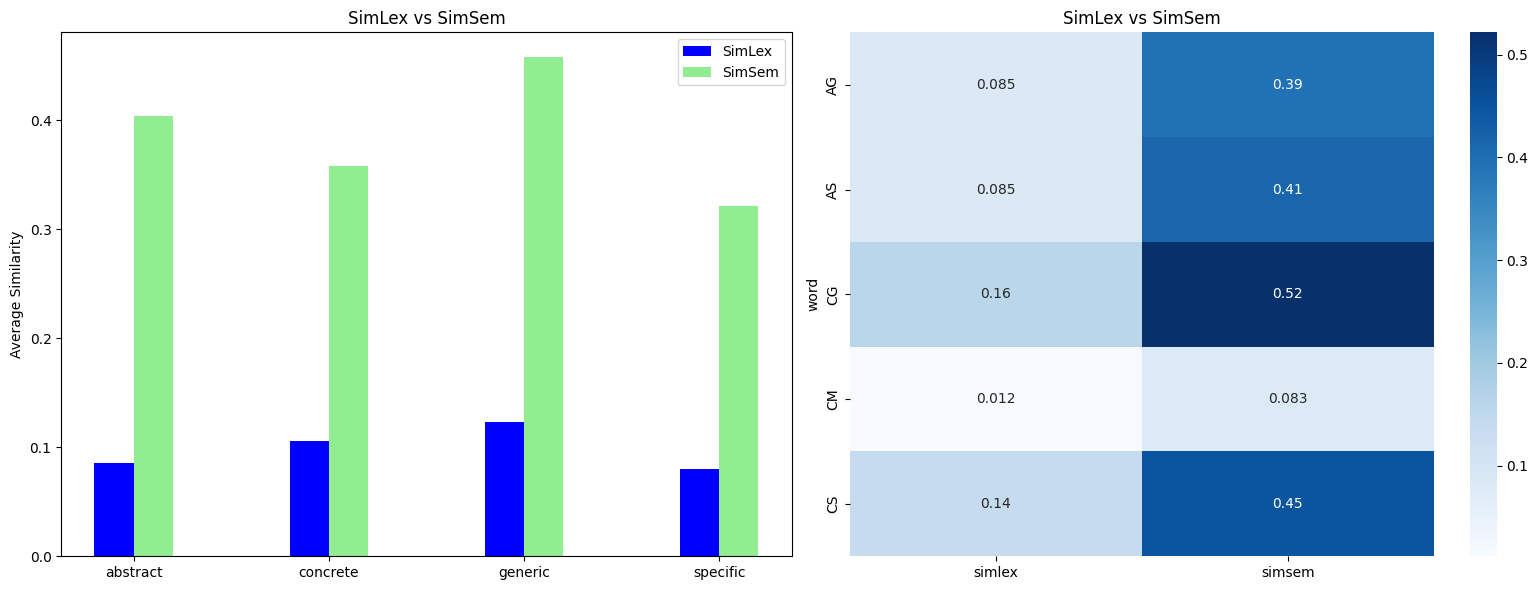

In [12]:
agg_concretness = (
    pairs_df
    .groupby("concretness")[["simlex", "simsem"]]
    .mean()
    .reset_index()
)

agg_specificity = (
    pairs_df
    .groupby("specificity")[["simlex", "simsem"]]
    .mean()
    .reset_index()
)

agg_4_groups = (
    pairs_df
    .groupby("word")[["simlex", "simsem"]]
    .mean()
    .reset_index()
)

df_heat = agg_4_groups.set_index("word")

fig, ax = plt.subplots(1, 2, figsize=(16, 6))

 
# Create a list of category labels by combining the concreteness groups (e.g., abstract/concrete)
# and the specificity groups (e.g., generic/specific) for use on the x-axis of the plot
labels = list(agg_concretness["concretness"]) + list(agg_specificity["specificity"])

simlex_vals = list(agg_concretness["simlex"]) + list(agg_specificity["simlex"])
simsem_vals = list(agg_concretness["simsem"]) + list(agg_specificity["simsem"])

# array of positions for the x-axis ticks
x_pos = np.arange(len(labels))
width = 0.2

ax[0].bar(x_pos - width/2, simlex_vals, width, label="SimLex", color="blue")
ax[0].bar(x_pos + width/2, simsem_vals, width, label="SimSem", color="lightgreen")

ax[0].set_xticks(x_pos)
ax[0].set_xticklabels(labels)
ax[0].set_ylabel("Average Similarity")
ax[0].set_title("SimLex vs SimSem")
ax[0].legend()


df_heat = agg_4_groups.set_index("word")

sns.heatmap(df_heat, annot=True, cmap="Blues", ax=ax[1])
ax[1].set_title("SimLex vs SimSem")

plt.tight_layout()
plt.show()